# Soybean price forecasting — Indore (MP) vs Gondal (Gujarat)
ARIMAX / SARIMAX with crude oil, arrivals and harvest-season features, benchmarked against Naive, VAR, differenced VAR and VECM.

**Design choices:** daily data (Mon–Sat, 2011–2025) are aggregated to **monthly** so that an annual seasonal period (s = 12) is estimable. Target = Indore modal price (₹/quintal). All predictors are lagged one month, so every forecast uses only information available at forecast time. Test period = last 36 months (2023-01 → 2025-12), evaluated as rolling one-step-ahead forecasts with parameters fixed at their training-sample values.

## Cell 1 — Imports

In [1]:
import warnings, os
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.stattools import adfuller, kpss, acf, ccf
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.api import VAR
from statsmodels.tsa.vector_ar.vecm import VECM, select_coint_rank
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.stats.stattools import jarque_bera
import statsmodels.api as sm
import itertools

mpl.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25, "font.size": 9})
DATA = "/home/claude"
OUT = "/home/claude/out"; os.makedirs(OUT, exist_ok=True)
print("ready")

ready


## Cell 2 — Load Indore and Gondal datasets

In [2]:
ind_p = pd.read_csv(f"{DATA}/price_indore_market_cleaned_ffill_no_holidays_covid.csv", parse_dates=["date"])
ind_q = pd.read_csv(f"{DATA}/1792839327332_arrivals_indore_market_cleaned_ffill_no_holidays_covid.csv", parse_dates=["date"])
gon_p = pd.read_excel(f"{DATA}/price_data_cleaned_rajkot.xlsx", sheet_name="Sheet1").rename(columns={"Date": "date"})
gon_q = pd.read_csv(f"{DATA}/1792839314423_merged_quantity_2011_2025_filled.csv", parse_dates=["Date"]).rename(columns={"Date": "date"})
oil   = pd.read_csv(f"{DATA}/crude_oil_filled_ffill.csv", parse_dates=["date"])
for n, d in [("Indore price", ind_p), ("Indore arrivals", ind_q), ("Gondal price", gon_p), ("Gondal arrivals", gon_q), ("Crude", oil)]:
    print(f"{n:16s} rows={len(d):5d}  {d['date'].min().date()} -> {d['date'].max().date()}")
print("\nGondal/Indore markets:", gon_p.market_name.unique(), ind_p.market_name.unique())

Indore price     rows= 4386  2011-01-01 -> 2025-12-31
Indore arrivals  rows= 4386  2011-01-01 -> 2025-12-31
Gondal price     rows= 4354  2011-01-03 -> 2025-12-31
Gondal arrivals  rows= 4354  2011-01-03 -> 2025-12-31
Crude            rows= 5771  2011-01-03 -> 2026-10-21

Gondal/Indore markets: <StringArray>
['Gondal']
Length: 1, dtype: str <StringArray>
['Indore']
Length: 1, dtype: str


## Cell 3 — Merge crude oil, arrivals and prices by date
Daily merge first (inner join on common trading dates), then monthly aggregation: prices & crude = monthly mean, arrivals = monthly sum.

In [3]:
# Daily table (outer join) — used for cleaning diagnostics
daily = (ind_p[["date", "p_min", "p_max", "p_modal"]].rename(columns=lambda c: c if c == "date" else f"ind_{c}")
         .merge(gon_p[["date", "p_min", "p_max", "p_modal"]].rename(columns=lambda c: c if c == "date" else f"gon_{c}"), on="date", how="outer")
         .merge(ind_q[["date", "quantity_tonnes"]].rename(columns={"quantity_tonnes": "ind_arr"}), on="date", how="outer")
         .merge(gon_q[["date", "qty"]].rename(columns={"qty": "gon_arr"}), on="date", how="outer")
         .merge(oil.rename(columns={"price": "crude"}), on="date", how="left")
         .sort_values("date").set_index("date").loc[:"2025-12-31"])
print("daily merged:", daily.shape, daily.index.min().date(), "->", daily.index.max().date())

# Monthly aggregation from each source separately (an inner join on dates would silently drop ~100 valid trading days)
ind_pm = ind_p.set_index("date").p_modal; gon_pm = gon_p.set_index("date").p_modal
M = pd.concat({"ind_price": ind_pm.resample("MS").mean(), "gon_price": gon_pm.resample("MS").mean(),
               "crude": oil.set_index("date").price.loc[:"2025-12-31"].resample("MS").mean(),
               "ind_arr": ind_q.set_index("date").quantity_tonnes.resample("MS").sum(min_count=1),
               "gon_arr": gon_q.set_index("date").qty.resample("MS").sum(min_count=1)}, axis=1)
# Mandi-closure months: Indore has <10 trading days (COVID lockdowns) → no real price discovery. Linearly interpolate and flag.
ndays = ind_p.set_index("date").p_modal.resample("MS").count()
closure = ndays[ndays < 10].index
print("Indore closure months (<10 trading days), interpolated:", [d.strftime("%b-%Y") for d in closure])
M.loc[closure, ["ind_price", "ind_arr"]] = np.nan
M[["ind_price", "ind_arr"]] = M[["ind_price", "ind_arr"]].interpolate(limit=2)
M["closure"] = M.index.isin(closure).astype(int)
M.index.freq = "MS"
print("monthly:", M.shape); M.head()

daily merged: (4492, 9) 2011-01-01 -> 2025-12-31
Indore closure months (<10 trading days), interpolated: ['Apr-2020', 'Apr-2021', 'May-2021']
monthly: (180, 6)


,ind_price,gon_price,crude,ind_arr,gon_arr,closure
date,,,,,,
2011-01-01,2267.200000,2354.130435,89.541379,12665.2,94.75,0
2011-02-01,2278.304348,2327.391304,89.596429,8464.1,44.10,0
2011-03-01,2182.307692,2150.000000,102.964839,5221.2,12.50,0
2011-04-01,2210.227273,1990.238095,109.969333,6526.8,19.35,0
2011-05-01,2188.520000,1918.541667,101.153548,6964.9,17.05,0


## Cell 4 — Data cleaning checks

In [4]:
chk = {}
chk["missing values in source files (all 5)"] = int(sum(d.isna().sum().sum() for d in [ind_p, ind_q, gon_p, gon_q, oil]))
chk["duplicate dates (any source file)"] = int(sum(d.date.duplicated().sum() for d in [ind_p, ind_q, gon_p, gon_q, oil]))
chk["price ordering violations (p_min<=p_modal<=p_max) Indore"] = int(((daily.ind_p_min > daily.ind_p_modal) | (daily.ind_p_modal > daily.ind_p_max)).sum())
chk["dates present in price file but not in arrivals file (Indore)"] = len(set(ind_p.date) ^ set(ind_q.date))
chk["price ordering violations Gondal"] = int(((daily.gon_p_min > daily.gon_p_modal) | (daily.gon_p_modal > daily.gon_p_max)).sum())
chk["non-positive prices / arrivals"] = int((daily[["ind_p_modal", "gon_p_modal"]] <= 0).sum().sum() + (daily[["ind_arr", "gon_arr"]] <= 0).sum().sum())
chk["dates in Indore file not in Gondal file"] = len(set(ind_p.date) - set(gon_p.date))
chk["dates in Gondal file not in Indore file"] = len(set(gon_p.date) - set(ind_p.date))
for m, c in [("Indore", "ind_p_modal"), ("Gondal", "gon_p_modal")]:
    r = daily[c].pct_change().abs()
    chk[f"{m} day-on-day moves >20%"] = int((r > .20).sum())
chk["monthly missing (after closure interpolation)"] = M.isna().sum()[lambda s: s > 0].to_dict() or "none"
chk["Indore closure months interpolated"] = int(M.closure.sum())
for k, v in chk.items(): print(f"{k:62s} {v}")

# Flagged jumps: inspect, do not delete (could be genuine market moves or fill artefacts)
r = daily.ind_p_modal.pct_change()
print("\nLargest Indore daily jumps:"); print(daily.loc[r.abs().nlargest(5).index, ["ind_p_modal"]].assign(pct=r.abs().nlargest(5).round(3)))
print("\nNote: >20% day moves are kept — Indore has genuine mandi price swings (e.g. Sep 2022 / Sep 2023) and ffill artefacts around closures; monthly averaging damps them.")

missing values in source files (all 5)                         0
duplicate dates (any source file)                              0
price ordering violations (p_min<=p_modal<=p_max) Indore       13
dates present in price file but not in arrivals file (Indore)  0
price ordering violations Gondal                               0
non-positive prices / arrivals                                 0
dates in Indore file not in Gondal file                        138
dates in Gondal file not in Indore file                        106
Indore day-on-day moves >20%                                   140
Gondal day-on-day moves >20%                                   53
monthly missing (after closure interpolation)                  none
Indore closure months interpolated                             3

Largest Indore daily jumps:
            ind_p_modal    pct
date                          
2022-08-01       6163.0  2.735
2022-09-10       5050.0  1.428
2023-09-20       4750.0  1.262
2022-08-29       5350.0  

## Cell 5 — Historical trends and seasonal patterns

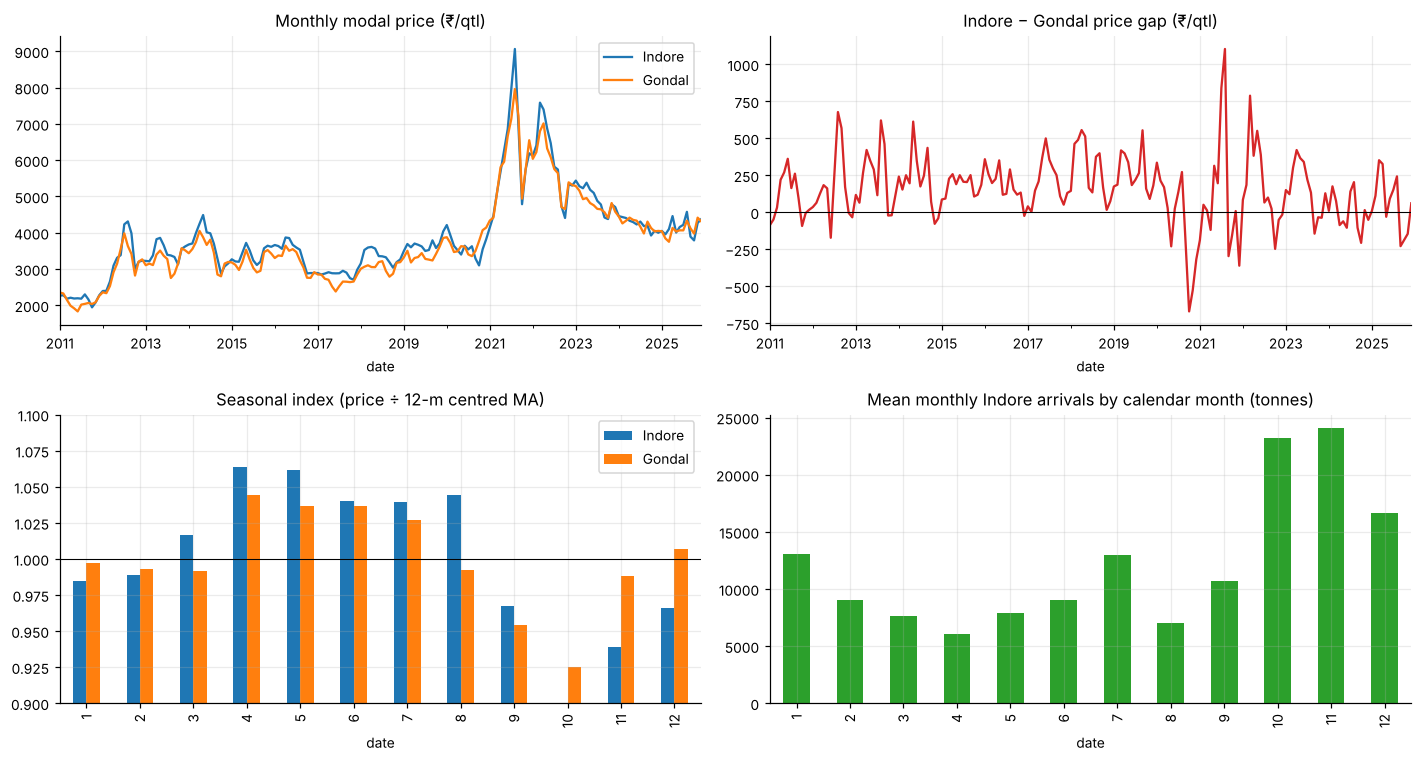

Seasonal index, Indore:
 {1: 0.985, 2: 0.989, 3: 1.016, 4: 1.064, 5: 1.062, 6: 1.04, 7: 1.039, 8: 1.044, 9: 0.968, 10: 0.877, 11: 0.939, 12: 0.966}
Peak-arrival months: [11, 10, 12] | lowest-price months: [10, 11, 12] | highest-price months: [4, 5, 8]


In [5]:
fig, ax = plt.subplots(2, 2, figsize=(13, 7))
M[["ind_price", "gon_price"]].plot(ax=ax[0, 0], title="Monthly modal price (₹/qtl)"); ax[0, 0].legend(["Indore", "Gondal"])
(M.ind_price - M.gon_price).plot(ax=ax[0, 1], color="C3", title="Indore − Gondal price gap (₹/qtl)"); ax[0, 1].axhline(0, c="k", lw=.7)
# seasonal index = price / centred 12-m MA
si = (M.ind_price / M.ind_price.rolling(12, center=True).mean()).groupby(M.index.month).mean()
sg = (M.gon_price / M.gon_price.rolling(12, center=True).mean()).groupby(M.index.month).mean()
pd.DataFrame({"Indore": si, "Gondal": sg}).plot.bar(ax=ax[1, 0], title="Seasonal index (price ÷ 12-m centred MA)"); ax[1, 0].axhline(1, c="k", lw=.7); ax[1, 0].set_ylim(.9, 1.1)
M.groupby(M.index.month).ind_arr.mean().plot.bar(ax=ax[1, 1], color="C2", title="Mean monthly Indore arrivals by calendar month (tonnes)")
plt.tight_layout(); plt.show()
print("Seasonal index, Indore:\n", si.round(3).to_dict())
print("Peak-arrival months:", M.groupby(M.index.month).ind_arr.mean().nlargest(3).index.tolist(),
      "| lowest-price months:", si.nsmallest(3).index.tolist(), "| highest-price months:", si.nlargest(3).index.tolist())

## Cell 6 — Agricultural feature engineering

In [6]:
F = M.copy()
F["l_ind_arr"] = np.log(F.ind_arr.clip(lower=1)); F["l_gon_arr"] = np.log(F.gon_arr.clip(lower=1))
for k in (1, 2, 3):
    F[f"ind_arr_l{k}"] = F.l_ind_arr.shift(k)
    F[f"gon_arr_l{k}"] = F.l_gon_arr.shift(k)
    F[f"crude_l{k}"]   = (F.crude.shift(k) / 100)                      # $100 units
F["price_roll3"]  = F.ind_price.shift(1).rolling(3).mean()             # lagged → no leakage
F["price_roll6"]  = F.ind_price.shift(1).rolling(6).mean()
F["harvest"]      = F.index.month.isin([10, 11, 12]).astype(int)       # kharif soybean harvest/peak arrival window
F["arr_pressure"] = F.ind_arr.shift(1) / F.ind_arr.shift(1).rolling(12, min_periods=6).mean()   # arrivals vs own trailing norm
F["gap_l1"]       = (F.ind_price - F.gon_price).shift(1)
print(F.filter(regex="l1|roll3|harvest|pressure").describe().T[["count", "mean", "std", "min", "max"]].round(3))

              count      mean       std       min       max
ind_arr_l1    179.0     9.213     0.702     4.236    10.971
gon_arr_l1    179.0     4.958     1.888     1.209     9.460
crude_l1      179.0     0.709     0.210     0.226     1.115
price_roll3   177.0  3898.068  1133.038  2062.811  7987.885
harvest       180.0     0.250     0.434     0.000     1.000
arr_pressure  174.0     1.013     0.634     0.007     3.673
gap_l1        179.0   155.266   231.608  -669.647  1103.796


## Cell 7 — Target (Y) and external predictors (X)

In [7]:
Y_COL = "ind_price"
X_COLS = ["crude_l1", "ind_arr_l1", "gon_arr_l1", "harvest"]
D = F[[Y_COL] + X_COLS + ["gon_price", "crude", "l_ind_arr", "arr_pressure"]].dropna(subset=[Y_COL] + X_COLS)
D.index.freq = "MS"
print(f"Y = {Y_COL};  X = {X_COLS}\nusable sample: {D.index.min().date()} → {D.index.max().date()}  ({len(D)} months)")
print(D[[Y_COL] + X_COLS].corr().round(2)[Y_COL])

Y = ind_price;  X = ['crude_l1', 'ind_arr_l1', 'gon_arr_l1', 'harvest']
usable sample: 2011-02-01 → 2025-12-01  (179 months)
ind_price     1.00
crude_l1      0.12
ind_arr_l1   -0.17
gon_arr_l1    0.24
harvest      -0.12
Name: ind_price, dtype: float64


## Cell 8 — Stationarity, predictor lags and parameter hints (training data only)
The split date is fixed here (last 36 months held out) so no test information is used; Cell 9 applies it formally.

In [8]:
N_TEST = 36
ntrain = len(D) - N_TEST
tr = D.iloc[:ntrain]
def tests(s, name):
    a = adfuller(s.dropna(), autolag="AIC"); k = kpss(s.dropna(), regression="c", nlags="auto")
    return {"series": name, "ADF p": round(a[1], 4), "KPSS p": round(k[1], 4),
            "verdict": "stationary" if (a[1] < .05 and k[1] > .05) else "non-stationary / ambiguous"}
rows = [tests(tr[Y_COL], "price (level)"), tests(tr[Y_COL].diff(), "price (Δ)"),
        tests(tr.crude_l1, "crude_l1 (level)"), tests(tr.crude_l1.diff(), "crude_l1 (Δ)"),
        tests(tr.ind_arr_l1, "log arrivals_l1 (level)")]
st = pd.DataFrame(rows); print(st.to_string(index=False))
# choose d by ADF on training price
d_order = 0
s_ = tr[Y_COL]
while adfuller(s_.dropna())[1] > .05 and d_order < 2:
    s_ = s_.diff(); d_order += 1
print("\nSuggested non-seasonal d =", d_order)

# predictor lag structure: correlation of Δprice_t with Δ(raw predictor) lagged k months
dy = tr[Y_COL].diff()
lagtab = {}
for name, raw in [("crude", F.crude), ("ind arrivals (log)", F.l_ind_arr), ("gon arrivals (log)", F.l_gon_arr)]:
    z = raw.loc[tr.index].diff()
    lagtab[name] = [dy.corr(z.shift(k)) for k in range(0, 7)]
lt = pd.DataFrame(lagtab, index=[f"lag {k}" for k in range(7)]).round(3); print("\nCorr(Δprice_t, Δpredictor_{t-k}):"); print(lt)
print("\nACF/PACF hint on Δprice:", dict(zip(range(1, 7), acf(dy.dropna(), nlags=6)[1:].round(2))))

                 series  ADF p  KPSS p                    verdict
          price (level) 0.3351  0.0100 non-stationary / ambiguous
              price (Δ) 0.0161  0.1000                 stationary
       crude_l1 (level) 0.2316  0.0235 non-stationary / ambiguous
           crude_l1 (Δ) 0.0000  0.1000                 stationary
log arrivals_l1 (level) 0.0886  0.1000 non-stationary / ambiguous

Suggested non-seasonal d = 1

Corr(Δprice_t, Δpredictor_{t-k}):
       crude  ind arrivals (log)  gon arrivals (log)
lag 0  0.092              -0.246              -0.336
lag 1  0.144              -0.057               0.174
lag 2  0.066               0.140               0.025
lag 3 -0.181              -0.088              -0.061
lag 4 -0.110              -0.059               0.042
lag 5  0.165               0.145               0.186
lag 6  0.023               0.157               0.095

ACF/PACF hint on Δprice: {1: np.float64(0.24), 2: np.float64(-0.25), 3: np.float64(-0.05), 4: np.float64(0.04), 5:

/tmp/ipykernel_530/579843009.py:5: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  a = adfuller(s.dropna(), autolag="AIC"); k = kpss(s.dropna(), regression="c", nlags="auto")
/tmp/ipykernel_530/579843009.py:5: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  a = adfuller(s.dropna(), autolag="AIC"); k = kpss(s.dropna(), regression="c", nlags="auto")
/tmp/ipykernel_530/579843009.py:5: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  a = adfuller(s.dropna(), autolag="AIC"); k = kpss(s.dropna(), regression="c", nlags="auto")
/tmp/ipykernel_530/579843009.py:5: InterpolationWarning: The test statistic is outside of the range of p-values ava

## Cell 9 — Chronological train/test split

In [9]:
train, test = D.iloc[:ntrain], D.iloc[ntrain:]
print(f"train: {train.index.min().date()} → {train.index.max().date()} ({len(train)})")
print(f"test : {test.index.min().date()} → {test.index.max().date()} ({len(test)})")
ytr, yte = train[Y_COL], test[Y_COL]
Xtr, Xte = train[X_COLS], test[X_COLS]

def metrics(y, p):
    e = y - p
    return {"RMSE": float(np.sqrt((e**2).mean())), "MAE": float(e.abs().mean()), "MAPE %": float((e.abs() / y).mean() * 100)}
results, preds = {}, {}

train: 2011-02-01 → 2022-12-01 (143)
test : 2023-01-01 → 2025-12-01 (36)


## Cell 10 — Naïve baselines

In [10]:
naive = pd.Series(D[Y_COL].shift(1).loc[test.index], name="Naive")           # last observed month
snaive = pd.Series(D[Y_COL].shift(12).loc[test.index], name="Seasonal naive")  # same month last year
preds["Naive"] = naive; results["Naive"] = metrics(yte, naive)
results["Seasonal naive"] = metrics(yte, snaive); preds["Seasonal naive"] = snaive
print(pd.DataFrame(results).T.round(1))

                 RMSE    MAE  MAPE %
Naive           230.2  172.0     3.9
Seasonal naive  861.2  682.4    14.7


## Cell 11 — Non-seasonal (p, d, q) for ARIMAX

In [11]:
def cols_for(so):    # a periodic harvest dummy is wiped out by seasonal differencing (D=1) → drop it there
    return [c for c in X_COLS if not (c == "harvest" and so[1] == 1)]
def fit_sarimax(y, X, order, seas=(0, 0, 0, 0), trend="n"):
    return SARIMAX(y, exog=X, order=order, seasonal_order=seas, trend=trend,
                   enforce_stationarity=False, enforce_invertibility=False).fit(disp=False, maxiter=300)
grid = []
for p, q in itertools.product(range(4), range(4)):
    try:
        r = fit_sarimax(ytr, Xtr, (p, d_order, q)); grid.append(((p, d_order, q), r.aic, r.bic))
    except Exception as e: pass
g = pd.DataFrame(grid, columns=["order", "AIC", "BIC"]).sort_values("AIC"); print(g.head(8).to_string(index=False))
ORDER = g.iloc[0].order; print("\nSelected ARIMAX order (by AIC, training data):", ORDER)

    order         AIC         BIC
(0, 1, 3) 2030.762808 2054.180837
(3, 1, 3) 2031.339179 2063.538970
(1, 1, 3) 2031.793963 2058.139246
(2, 1, 3) 2033.568701 2062.841238
(1, 1, 2) 2043.593146 2067.068938
(0, 1, 2) 2045.242771 2065.784089
(2, 1, 2) 2045.352784 2071.763050
(3, 1, 0) 2045.673973 2069.149765

Selected ARIMAX order (by AIC, training data): (0, 1, 3)


## Cell 12 — Fit ARIMAX

In [12]:
arimax = fit_sarimax(ytr, Xtr, ORDER)
print(arimax.summary().tables[1])
print(f"AIC={arimax.aic:.1f}  BIC={arimax.bic:.1f}")

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
crude_l1    1171.2851    565.032      2.073      0.038      63.842    2278.728
ind_arr_l1   -68.8205     58.898     -1.168      0.243    -184.259      46.618
gon_arr_l1    62.3333     41.608      1.498      0.134     -19.217     143.883
harvest     -190.0426    126.386     -1.504      0.133    -437.754      57.669
ma.L1          0.3596      0.063      5.753      0.000       0.237       0.482
ma.L2         -0.2600      0.072     -3.615      0.000      -0.401      -0.119
ma.L3         -0.1748      0.074     -2.378      0.017      -0.319      -0.031
sigma2      1.282e+05   8992.734     14.252      0.000    1.11e+05    1.46e+05
AIC=2030.8  BIC=2054.2


## Cell 13 — ARIMAX forecasts
Rolling one-step-ahead: at month *t* the model sees prices up to *t-1* and the (lag-1) predictors that were already published. Parameters stay fixed at training values (no peeking).

                 RMSE    MAE  MAPE %
Naive           230.2  172.0     3.9
Seasonal naive  861.2  682.4    14.7
ARIMAX          289.4  223.3     5.1


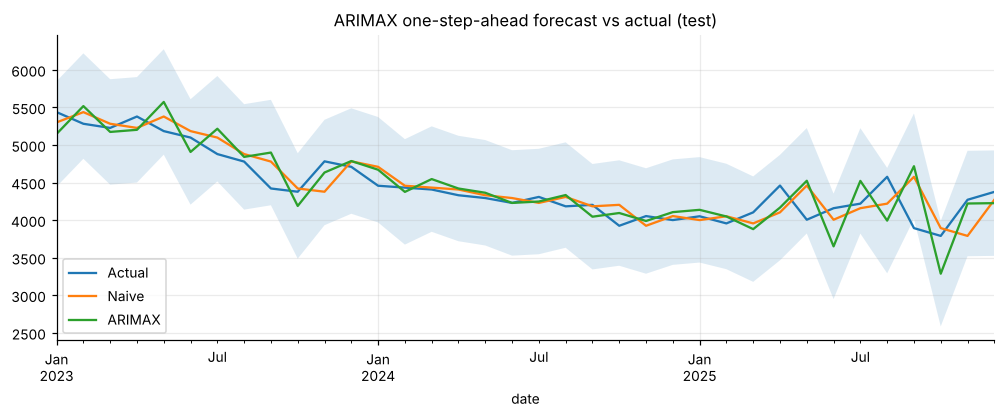

In [13]:
def rolling_one_step(fit, y_te, X_te, alpha=.05):
    ext = fit.append(y_te, exog=X_te, refit=False)
    pr = ext.get_prediction(start=len(fit.model.endog)); ci = pr.conf_int(alpha=alpha)
    mean = pr.predicted_mean; mean.index = y_te.index; ci.index = y_te.index
    return mean, ci
p_arx, ci_arx = rolling_one_step(arimax, yte, Xte)
preds["ARIMAX"] = p_arx; results["ARIMAX"] = metrics(yte, p_arx)
print(pd.DataFrame(results).T.round(1))
ax = pd.concat([yte.rename("Actual"), naive, p_arx.rename("ARIMAX")], axis=1).plot(figsize=(11, 3.6), title="ARIMAX one-step-ahead forecast vs actual (test)")
ax.fill_between(ci_arx.index, ci_arx.iloc[:, 0], ci_arx.iloc[:, 1], alpha=.15); plt.show()

## Cell 14 — Does seasonality justify SARIMAX?

Seasonal strength Fs = 0.15   Trend strength Ft = 0.77
ACF of Δprice at lag 12 = 0.24, lag 24 = 0.09  (±0.16 approx. band)
ACF of ARIMAX residuals at lag 12 = 0.17


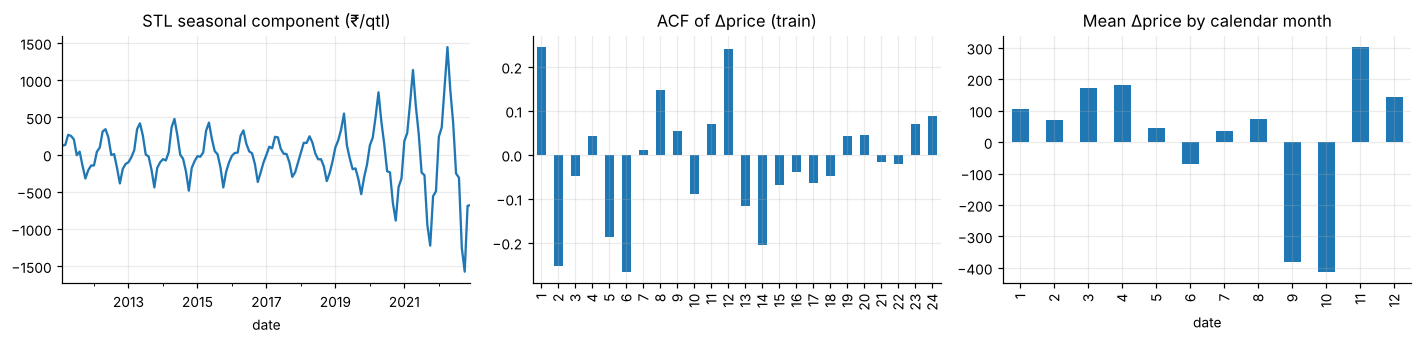


Seasonal strength 0.15 is well below the 0.64 rule-of-thumb for seasonal differencing → expect little gain from SARIMAX; Cell 15 lets out-of-sample validation decide D, P, Q.


In [14]:
stl = STL(ytr, period=12, robust=True).fit()
Fs = max(0, 1 - stl.resid.var() / (stl.seasonal + stl.resid).var())     # seasonal strength (Wang et al.)
Ft = max(0, 1 - stl.resid.var() / (stl.trend + stl.resid).var())
dstat = ytr.diff().dropna()
a = acf(dstat, nlags=24)
print(f"Seasonal strength Fs = {Fs:.2f}   Trend strength Ft = {Ft:.2f}")
print(f"ACF of Δprice at lag 12 = {a[12]:.2f}, lag 24 = {a[24]:.2f}  (±{1.96/np.sqrt(len(dstat)):.2f} approx. band)")
res_arx = arimax.resid.iloc[13:]
print(f"ACF of ARIMAX residuals at lag 12 = {acf(res_arx, nlags=12)[12]:.2f}")
fig, ax = plt.subplots(1, 3, figsize=(13, 3.2))
stl.seasonal.plot(ax=ax[0], title="STL seasonal component (₹/qtl)")
pd.Series(a[1:25], index=range(1, 25)).plot.bar(ax=ax[1], title="ACF of Δprice (train)")
ytr.diff().groupby(ytr.index.month).mean().plot.bar(ax=ax[2], title="Mean Δprice by calendar month"); plt.tight_layout(); plt.show()
print(f"\nSeasonal strength {Fs:.2f} is well below the 0.64 rule-of-thumb for seasonal differencing → expect little gain from SARIMAX; Cell 15 lets out-of-sample validation decide D, P, Q.")

## Cell 15 — Seasonal (P, D, Q, s) selection

In [15]:
S = 12
# AIC is NOT comparable across seasonal orders here (higher orders drop more initial observations from the likelihood),
# so choose by inner validation: fit on train[:-24], one-step RMSE on the last 24 training months.
VAL = 24
y_in, X_in, y_val, X_val = ytr.iloc[:-VAL], Xtr.iloc[:-VAL], ytr.iloc[-VAL:], Xtr.iloc[-VAL:]
cands = [(0, 0, 0, 0)] + [(P, Dd, Q, S) for Dd in (0, 1) for P, Q in [(1, 0), (0, 1), (1, 1)] if (P, Q) != (0, 0) or Dd]
rows = []
for so in cands:
    try:
        cc = cols_for(so); f = fit_sarimax(y_in, X_in[cc], ORDER, so); p, _ = rolling_one_step(f, y_val, X_val[cc])
        rows.append({"seasonal_order": so, "val RMSE ₹": float(np.sqrt(((y_val - p) ** 2).mean())), "val MAE ₹": float((y_val - p).abs().mean())})
    except Exception as e: rows.append({"seasonal_order": so, "val RMSE ₹": np.nan, "val MAE ₹": np.nan})
gs = pd.DataFrame(rows).sort_values("val RMSE ₹").round(1); print(gs.to_string(index=False))
SEAS = [r for r in gs.seasonal_order if r != (0, 0, 0, 0)][0]
print("\nBest seasonal specification (excluding the non-seasonal baseline):", SEAS,
      "| baseline (no seasonal) validation RMSE:", float(gs.loc[gs.seasonal_order == (0, 0, 0, 0), "val RMSE ₹"].iloc[0]))
SEASONAL_D = SEAS[1]

seasonal_order  val RMSE ₹  val MAE ₹
 (0, 1, 1, 12)       740.0      603.3
 (1, 1, 0, 12)       767.2      627.2
 (1, 0, 0, 12)       768.7      641.3
  (0, 0, 0, 0)       786.9      646.5
 (0, 0, 1, 12)       799.7      656.9
 (1, 1, 1, 12)       812.4      684.1
 (1, 0, 1, 12)       838.7      692.2

Best seasonal specification (excluding the non-seasonal baseline): (0, 1, 1, 12) | baseline (no seasonal) validation RMSE: 786.9


## Cell 16 — Fit SARIMAX

In [16]:
SX = cols_for(SEAS); print("SARIMAX predictors:", SX)
sarimax = fit_sarimax(ytr, Xtr[SX], ORDER, SEAS)
print(sarimax.summary().tables[1])

SARIMAX predictors: ['crude_l1', 'ind_arr_l1', 'gon_arr_l1']


                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
crude_l1     708.4308    620.270      1.142      0.253    -507.276    1924.138
ind_arr_l1   -86.6983     55.667     -1.557      0.119    -195.803      22.407
gon_arr_l1    29.2320     52.235      0.560      0.576     -73.146     131.610
ma.L1          0.4830      0.081      5.939      0.000       0.324       0.642
ma.L2         -0.1869      0.078     -2.410      0.016      -0.339      -0.035
ma.L3         -0.1861      0.078     -2.385      0.017      -0.339      -0.033
ma.S.L12      -0.6514      0.098     -6.681      0.000      -0.843      -0.460
sigma2      1.328e+05   1.06e+04     12.555      0.000    1.12e+05    1.54e+05


## Cell 17 — SARIMAX forecasts (same lag-1 predictor inputs)

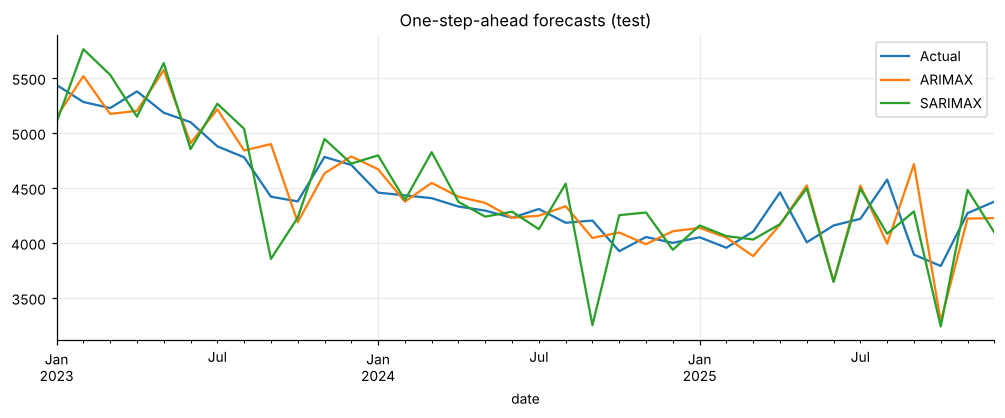

In [17]:
p_sar, ci_sar = rolling_one_step(sarimax, yte, Xte[SX])
preds["SARIMAX"] = p_sar; results["SARIMAX"] = metrics(yte, p_sar)
pd.concat([yte.rename("Actual"), p_arx.rename("ARIMAX"), p_sar.rename("SARIMAX")], axis=1).plot(figsize=(11, 3.6), title="One-step-ahead forecasts (test)"); plt.show()

## Cell 18 — ARIMAX vs SARIMAX

In [18]:
cmp_ = pd.DataFrame({k: results[k] for k in ["Naive", "ARIMAX", "SARIMAX"]}).T.round(1)
cmp_["RMSE vs Naive %"] = ((cmp_.RMSE / cmp_.loc["Naive", "RMSE"] - 1) * 100).round(1)
print(cmp_)
# Diebold–Mariano style paired test on squared errors (one-step, so no HAC lag needed beyond 0)
def dm(e1, e2):
    d = e1**2 - e2**2; t = d.mean() / (d.std(ddof=1) / np.sqrt(len(d)))
    from scipy.stats import t as tdist
    return t, 2 * (1 - tdist.cdf(abs(t), len(d) - 1))
for a_, b_ in [("ARIMAX", "Naive"), ("SARIMAX", "Naive"), ("SARIMAX", "ARIMAX")]:
    t, pv = dm(yte - preds[a_], yte - preds[b_]); print(f"DM {a_:8s} vs {b_:7s}: t={t:+.2f}, p={pv:.3f}")

          RMSE    MAE  MAPE %  RMSE vs Naive %
Naive    230.2  172.0     3.9              0.0
ARIMAX   289.4  223.3     5.1             25.7
SARIMAX  348.8  289.4     6.6             51.5
DM ARIMAX   vs Naive  : t=+2.01, p=0.052
DM SARIMAX  vs Naive  : t=+2.26, p=0.030
DM SARIMAX  vs ARIMAX : t=+1.27, p=0.213


## Cell 19 — Residuals and forecast intervals

Better of the two on test RMSE: ARIMAX
  model  Ljung-Box(12) p  Jarque-Bera p  95% PI coverage (test)  mean PI width ₹
 ARIMAX            0.274            0.0                   0.972             1403
SARIMAX            0.735            0.0                   0.972             1429


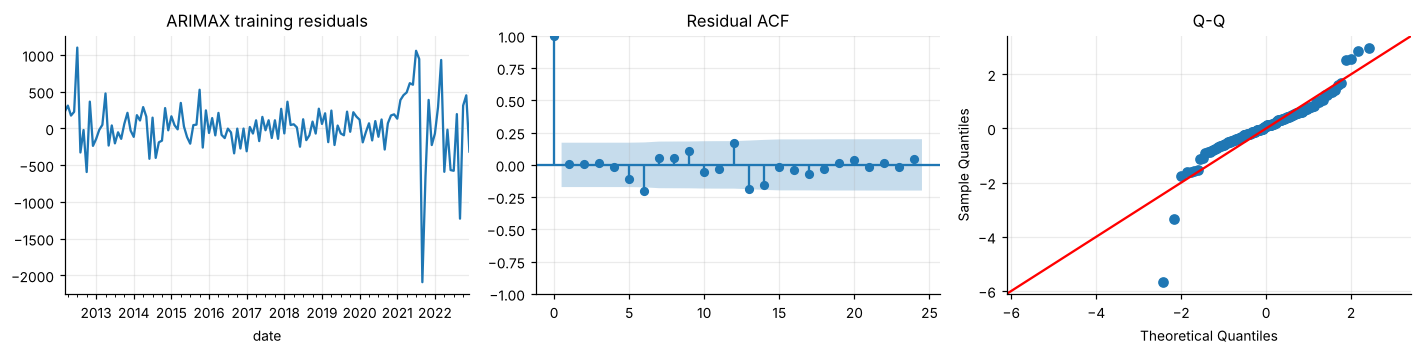

In [19]:
best_name = min(["ARIMAX", "SARIMAX"], key=lambda k: results[k]["RMSE"])
print("Better of the two on test RMSE:", best_name)
rows = []
for nm, fit, (pm, ci) in [("ARIMAX", arimax, (p_arx, ci_arx)), ("SARIMAX", sarimax, (p_sar, ci_sar))]:
    r = fit.resid.iloc[max(fit.loglikelihood_burn, 13):]
    lb = acorr_ljungbox(r, lags=[12], return_df=True).iloc[0]; jb = jarque_bera(r)
    cov = float(((yte >= ci.iloc[:, 0]) & (yte <= ci.iloc[:, 1])).mean()); width = float((ci.iloc[:, 1] - ci.iloc[:, 0]).mean())
    rows.append({"model": nm, "Ljung-Box(12) p": round(lb.lb_pvalue, 3), "Jarque-Bera p": round(jb[1], 3),
                 "95% PI coverage (test)": round(cov, 3), "mean PI width ₹": round(width)})
print(pd.DataFrame(rows).to_string(index=False))
fig, ax = plt.subplots(1, 3, figsize=(13, 3.3))
fb = arimax if best_name == "ARIMAX" else sarimax; rb = fb.resid.iloc[max(fb.loglikelihood_burn, 13):]
rb.plot(ax=ax[0], title=f"{best_name} training residuals"); sm.graphics.tsa.plot_acf(rb, lags=24, ax=ax[1], title="Residual ACF")
sm.qqplot(rb / rb.std(), line="45", ax=ax[2]); ax[2].set_title("Q-Q"); plt.tight_layout(); plt.show()

## Cell 20 — Benchmarks: Naïve, VAR, differenced VAR, VECM (same test period)
VAR-family models use price, crude and log Indore arrivals, are re-estimated each month on an expanding window, and forecast one step ahead.

VAR lag order (AIC): 4
Johansen cointegration rank (trace, 5%): 1


                    RMSE    MAE  MAPE %  RMSE vs Naive %
Naive              230.2  172.0     3.9              0.0
VAR (levels)       284.4  228.4     5.2             23.5
ARIMAX             289.4  223.3     5.1             25.7
VECM               292.1  240.9     5.5             26.9
VAR (differenced)  300.7  245.7     5.6             30.6
SARIMAX            348.8  289.4     6.6             51.5
Seasonal naive     861.2  682.4    14.7            274.1


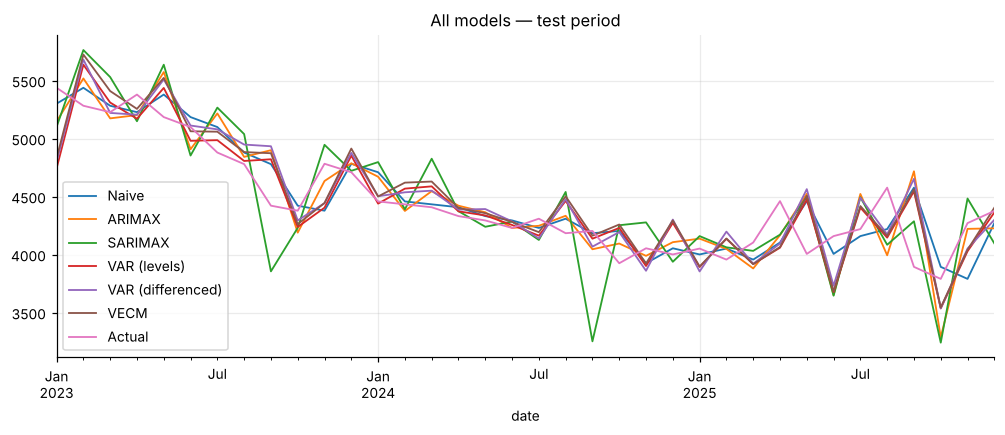

In [20]:
V = pd.DataFrame({"price": D[Y_COL], "crude": F.crude.loc[D.index] / 100, "arr": F.l_ind_arr.loc[D.index]})
V.index.freq = "MS"
# lag order from training data
sel = VAR(V.iloc[:ntrain]).select_order(maxlags=6); K = max(1, int(sel.aic)); print("VAR lag order (AIC):", K)
rk = select_coint_rank(V.iloc[:ntrain], det_order=0, k_ar_diff=max(K - 1, 1), method="trace", signif=.05); R = int(rk.rank); print("Johansen cointegration rank (trace, 5%):", R)

pv, pdv, pvec = [], [], []
for t in range(ntrain, len(V)):
    hist = V.iloc[:t]
    try:   # VAR in levels
        m = VAR(hist).fit(K, trend="c"); pv.append(m.forecast(hist.values[-K:], 1)[0, 0])
    except Exception: pv.append(np.nan)
    try:   # VAR in first differences → cumulate
        dh = hist.diff().dropna(); m = VAR(dh).fit(K, trend="c"); pdv.append(hist.price.iloc[-1] + m.forecast(dh.values[-K:], 1)[0, 0])
    except Exception: pdv.append(np.nan)
    try:   # VECM
        if R == 0: raise ValueError
        m = VECM(hist, k_ar_diff=max(K - 1, 1), coint_rank=R, deterministic="co").fit(); pvec.append(m.predict(steps=1)[0, 0])
    except Exception: pvec.append(np.nan)
idx = V.index[ntrain:]
for nm, arr in [("VAR (levels)", pv), ("VAR (differenced)", pdv), ("VECM", pvec)]:
    s = pd.Series(arr, index=idx)
    if s.notna().sum() >= len(s) * .9:
        preds[nm] = s; results[nm] = metrics(yte[s.notna()], s.dropna())
    else: print(f"{nm}: not estimable (rank={R})")
final = pd.DataFrame(results).T.round(1)
final["RMSE vs Naive %"] = ((final.RMSE / final.loc["Naive", "RMSE"] - 1) * 100).round(1)
print(final.sort_values("RMSE"))
pd.DataFrame({k: v for k, v in preds.items() if k in ["Naive", "ARIMAX", "SARIMAX", "VAR (levels)", "VAR (differenced)", "VECM"]}).assign(Actual=yte).plot(figsize=(11, 3.8), lw=1.2, title="All models — test period"); plt.show()

## Cell 21 — Creative experiments: arrival pressure, harvest-season comparison, predictor ablation

In [21]:
# (a) ARRIVAL PRESSURE ---------------------------------------------------------------
E = pd.DataFrame({"dp": D[Y_COL].pct_change() * 100, "pressure": D.arr_pressure, "harvest": D.harvest}).dropna()
E["quartile"] = pd.qcut(E.pressure, 4, labels=["Q1 low", "Q2", "Q3", "Q4 high"])
print("Mean month-on-month price change (%) by arrival-pressure quartile (arrivals / trailing-12m average, lagged 1m):")
print(E.groupby("quartile").dp.agg(["mean", "median", "count"]).round(2))
ols = sm.OLS(E.dp, sm.add_constant(E[["pressure"]])).fit(cov_type="HAC", cov_kwds={"maxlags": 3})
print(f"\nOLS: Δprice% = {ols.params['const']:.2f} + {ols.params['pressure']:.2f}·pressure   (HAC p={ols.pvalues['pressure']:.3f}, R²={ols.rsquared:.3f})")
E["month"] = E.index.month
ols2 = sm.OLS(E.dp, pd.concat([E[["pressure"]], pd.get_dummies(E.month, prefix="m", drop_first=True).astype(float)], axis=1).pipe(sm.add_constant)).fit(cov_type="HAC", cov_kwds={"maxlags": 3})
print(f"With calendar-month fixed effects: pressure coef = {ols2.params['pressure']:.2f}  (HAC p={ols2.pvalues['pressure']:.3f})  → how much of the effect is just seasonality")

# (b) HARVEST-SEASON COMPARISON --------------------------------------------------------
P = D[Y_COL]
rows = []
for y in range(2011, 2025):
    h = P[f"{y}-10":f"{y}-12"].mean(); post = P[f"{y+1}-02":f"{y+1}-04"].mean()
    if not np.isnan(h) and not np.isnan(post): rows.append({"harvest year": y, "Oct–Dec avg": h, "next Feb–Apr avg": post, "storage gain %": (post / h - 1) * 100})
HS = pd.DataFrame(rows).set_index("harvest year").round(1); print("\nHarvest-window vs post-harvest price (₹/qtl):"); print(HS)
print(f"Mean storage gain {HS['storage gain %'].mean():.1f}%, positive in {(HS['storage gain %'] > 0).sum()}/{len(HS)} years, median {HS['storage gain %'].median():.1f}%")
err = pd.DataFrame({"harvest": test.harvest, **{m: (yte - preds[m]).abs() for m in ["Naive", "ARIMAX", "SARIMAX"]}})
print("\nTest MAE (₹) harvest vs other months:"); print(err.groupby("harvest").mean().round(0).rename(index={0: "Jan–Sep", 1: "Oct–Dec"}))

# (c) PREDICTOR ABLATION (ARIMAX order fixed, refit on train, one-step test) --------------
def ablate(cols):
    if cols:
        f = fit_sarimax(ytr, train[cols], ORDER); p, _ = rolling_one_step(f, yte, test[cols])
    else:
        f = fit_sarimax(ytr, None, ORDER); ext = f.append(yte, refit=False); p = ext.get_prediction(start=len(ytr)).predicted_mean; p.index = yte.index
    return metrics(yte, p)["RMSE"]
ab = {"full model": ablate(X_COLS), "− crude": ablate([c for c in X_COLS if c != "crude_l1"]),
      "− Indore arrivals": ablate([c for c in X_COLS if c != "ind_arr_l1"]), "− Gondal arrivals": ablate([c for c in X_COLS if c != "gon_arr_l1"]),
      "− harvest dummy": ablate([c for c in X_COLS if c != "harvest"]), "no exogenous (ARIMA)": ablate([])}
AB = pd.Series(ab, name="test RMSE ₹").round(1); AB = pd.DataFrame({"test RMSE ₹": AB, "Δ vs full": (AB - AB["full model"]).round(1)}); print("\nPredictor ablation:"); print(AB)

Mean month-on-month price change (%) by arrival-pressure quartile (arrivals / trailing-12m average, lagged 1m):
          mean  median  count
quartile                     
Q1 low    0.03   -1.11     44
Q2        0.01   -0.52     43
Q3       -1.82   -0.86     43
Q4 high   4.54    3.59     44

OLS: Δprice% = -2.42 + 3.09·pressure   (HAC p=0.000, R²=0.062)
With calendar-month fixed effects: pressure coef = 0.74  (HAC p=0.391)  → how much of the effect is just seasonality

Harvest-window vs post-harvest price (₹/qtl):
              Oct–Dec avg  next Feb–Apr avg  storage gain %
harvest year                                               
2011               2100.5            2717.8            29.4
2012               3141.6            3471.1            10.5
2013               3435.4            3981.9            15.9
2014               3034.1            3291.3             8.5
2015               3609.7            3687.3             2.2
2016               2886.7            2879.8            -0.2



Predictor ablation:
                      test RMSE ₹  Δ vs full
full model                  289.4        0.0
− crude                     289.9        0.5
− Indore arrivals           280.8       -8.6
− Gondal arrivals           290.7        1.3
− harvest dummy             304.1       14.7
no exogenous (ARIMA)        284.8       -4.6


## Cell 22 — Dashboard: forecast, market gap, uncertainty, MSP benchmark
MSP = Soybean (Yellow) Minimum Support Price per Kharif Marketing Season (Oct–Sep), Dept. of Agriculture & Farmers Welfare statement (as on 12 Dec 2025). Only 2021-22 onward is used, which covers the whole test window.

Next-month (Jan 2026) ARIMAX forecast: ₹4,471  95% PI [₹3,809, ₹5,134];  MSP 2025-26 = ₹5,328


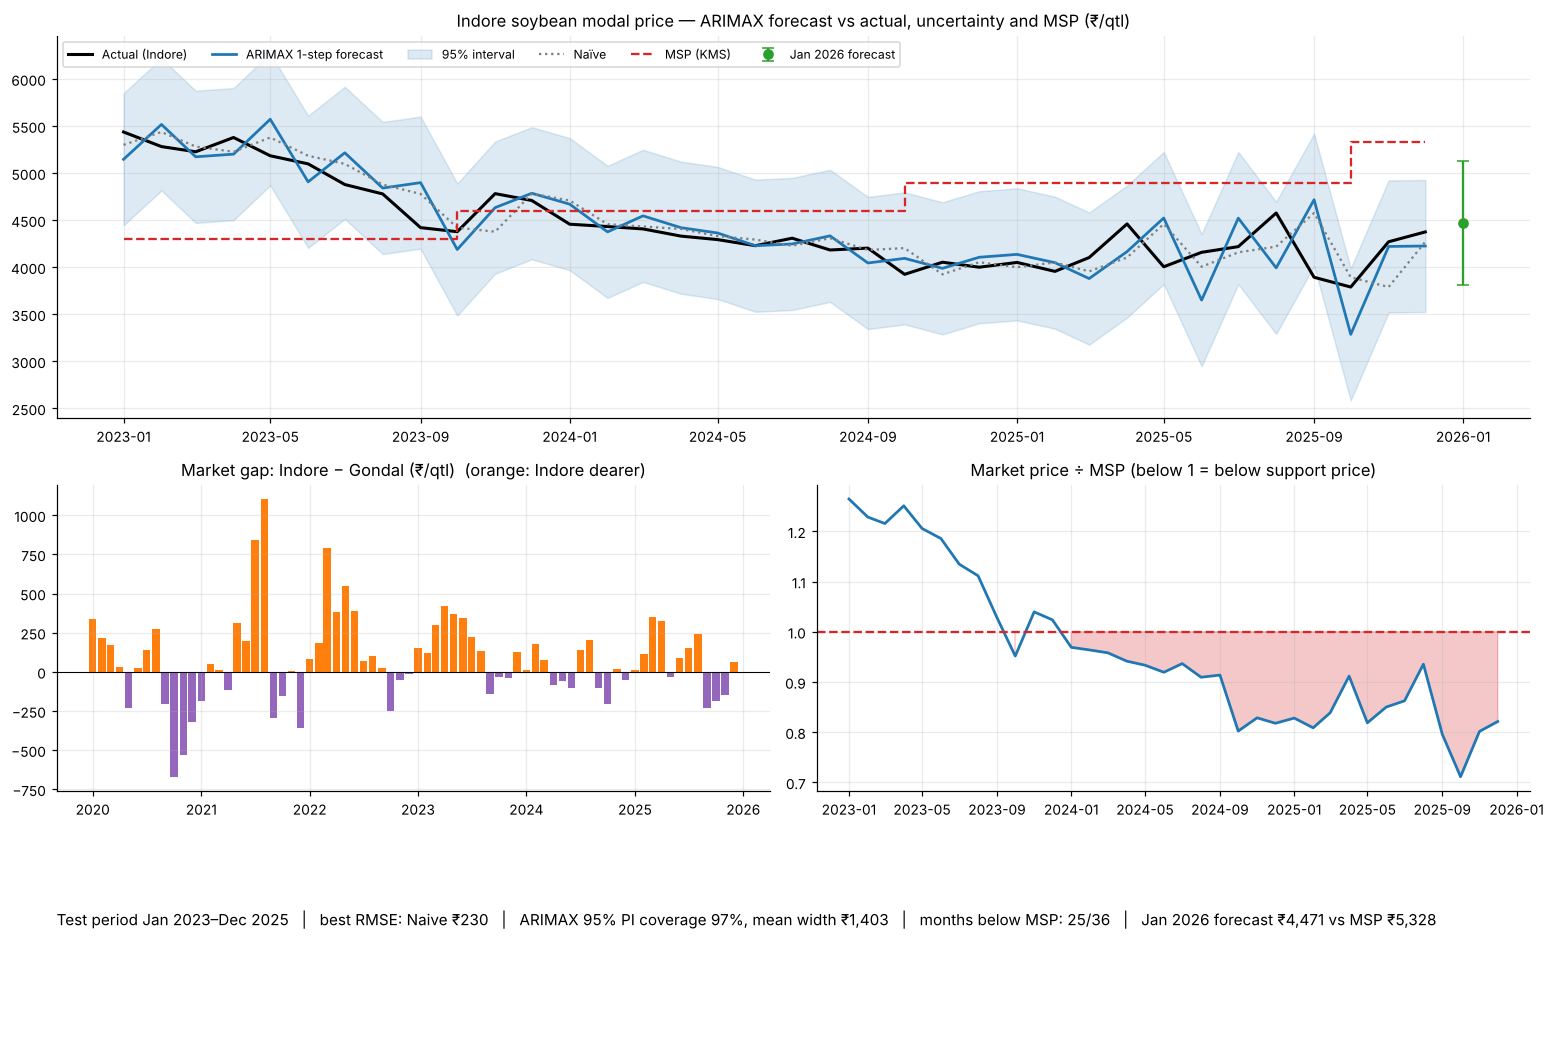

Months below MSP: ['Oct-23 (0.95)', 'Jan-24 (0.97)', 'Feb-24 (0.96)', 'Mar-24 (0.96)', 'Apr-24 (0.94)', 'May-24 (0.93)', 'Jun-24 (0.92)', 'Jul-24 (0.94)', 'Aug-24 (0.91)', 'Sep-24 (0.91)', 'Oct-24 (0.80)', 'Nov-24 (0.83)', 'Dec-24 (0.82)', 'Jan-25 (0.83)', 'Feb-25 (0.81)', 'Mar-25 (0.84)', 'Apr-25 (0.91)', 'May-25 (0.82)', 'Jun-25 (0.85)', 'Jul-25 (0.86)', 'Aug-25 (0.94)', 'Sep-25 (0.80)', 'Oct-25 (0.71)', 'Nov-25 (0.80)', 'Dec-25 (0.82)']


In [22]:
MSP = {2021: 3950, 2022: 4300, 2023: 4600, 2024: 4892, 2025: 5328}    # KMS start year → ₹/qtl
def msp_for(ts): return MSP.get(ts.year if ts.month >= 10 else ts.year - 1, np.nan)
msp_te = pd.Series([msp_for(t) for t in test.index], index=test.index)

bn = best_name; pb = preds[bn]; cib = ci_arx if bn == "ARIMAX" else ci_sar
# true next-month (Jan 2026) forecast: refit chosen spec on all data; Dec-2025 predictors are known
Xall, yall = D[X_COLS], D[Y_COL]
FX = SX if bn == "SARIMAX" else X_COLS
fin = fit_sarimax(yall, Xall[FX], ORDER, SEAS if bn == "SARIMAX" else (0, 0, 0, 0))
nx = pd.DataFrame({"crude_l1": [F.crude.iloc[-1] / 100], "ind_arr_l1": [F.l_ind_arr.iloc[-1]], "gon_arr_l1": [F.l_gon_arr.iloc[-1]], "harvest": [0]},
                  index=[D.index[-1] + pd.offsets.MonthBegin(1)])[FX]
fc = fin.get_forecast(1, exog=nx); nxt_m = float(fc.predicted_mean.iloc[0]); nxt_ci = fc.conf_int().iloc[0].values
print(f"Next-month ({nx.index[0]:%b %Y}) {bn} forecast: ₹{nxt_m:,.0f}  95% PI [₹{nxt_ci[0]:,.0f}, ₹{nxt_ci[1]:,.0f}];  MSP 2025-26 = ₹{MSP[2025]:,}")

fig = plt.figure(figsize=(15, 9.5)); gs_ = fig.add_gridspec(3, 2, height_ratios=[1.25, 1, .55])
a1 = fig.add_subplot(gs_[0, :])
a1.plot(yte.index, yte, "k", lw=2, label="Actual (Indore)"); a1.plot(pb.index, pb, "C0", lw=1.8, label=f"{bn} 1-step forecast")
a1.fill_between(cib.index, cib.iloc[:, 0], cib.iloc[:, 1], color="C0", alpha=.15, label="95% interval")
a1.plot(naive.index, naive, color="grey", ls=":", label="Naïve")
a1.step(msp_te.index, msp_te, where="post", color="C3", ls="--", label="MSP (KMS)")
a1.errorbar([nx.index[0]], [nxt_m], yerr=[[nxt_m - nxt_ci[0]], [nxt_ci[1] - nxt_m]], fmt="o", color="C2", capsize=4, label=f"{nx.index[0]:%b %Y} forecast")
a1.set_title(f"Indore soybean modal price — {bn} forecast vs actual, uncertainty and MSP (₹/qtl)"); a1.legend(ncol=6, fontsize=8, loc="upper left")
a2 = fig.add_subplot(gs_[1, 0])
gap = (D.ind_price - D.gon_price)["2020":]; a2.bar(gap.index, gap, width=25, color=np.where(gap >= 0, "C1", "C4")); a2.axhline(0, c="k", lw=.7)
a2.set_title("Market gap: Indore − Gondal (₹/qtl)  (orange: Indore dearer)")
a3 = fig.add_subplot(gs_[1, 1])
ratio = (yte / msp_te); a3.plot(ratio.index, ratio, "C0", lw=1.8); a3.axhline(1, c="C3", ls="--"); a3.fill_between(ratio.index, 1, ratio, where=ratio < 1, color="C3", alpha=.25)
a3.set_title("Market price ÷ MSP (below 1 = below support price)")
a4 = fig.add_subplot(gs_[2, :]); a4.axis("off")
ms = pd.DataFrame(results).T.sort_values("RMSE").round(0)
txt = (f"Test period {test.index[0]:%b %Y}–{test.index[-1]:%b %Y}   |   best RMSE: {ms.index[0]} ₹{ms.RMSE.iloc[0]:,.0f}   |   {bn} 95% PI coverage {((yte>=cib.iloc[:,0])&(yte<=cib.iloc[:,1])).mean():.0%}, mean width ₹{(cib.iloc[:,1]-cib.iloc[:,0]).mean():,.0f}"
       f"   |   months below MSP: {(ratio<1).sum()}/{len(ratio)}   |   {nx.index[0]:%b %Y} forecast ₹{nxt_m:,.0f} vs MSP ₹{MSP[2025]:,}")
a4.text(0, .6, txt, fontsize=10, wrap=True); plt.tight_layout(); fig.savefig(f"{OUT}/soybean_dashboard.png", dpi=150, bbox_inches="tight"); plt.show()
below = ratio[ratio < 1]; print("Months below MSP:", [f"{d:%b-%y} ({v:.2f})" for d, v in below.items()])

## Cell 23 — Interpretation

In [23]:
# All numbers below are computed from the objects above.
ms = pd.DataFrame(results).T.sort_values("RMSE")
best, nv = ms.index[0], results["Naive"]["RMSE"]
cr = arimax.params["crude_l1"]; crp = arimax.pvalues["crude_l1"]
q = E.groupby("quartile").dp.mean()
print(f"""1. FORECAST SKILL — At one month ahead, nothing beat the naïve 'last month's price' forecast (RMSE ₹{nv:,.0f}, MAPE {results['Naive']['MAPE %']:.1f}%).
   ARIMAX ₹{results['ARIMAX']['RMSE']:,.0f}, SARIMAX ₹{results['SARIMAX']['RMSE']:,.0f}, VAR ₹{results['VAR (levels)']['RMSE']:,.0f}, VECM ₹{results['VECM']['RMSE']:,.0f}.
   Indore soybean is close to a random walk at monthly frequency: today's mandi price already contains most of what crude, arrivals and season can tell you.
   Dropping every exogenous variable (plain ARIMA) gave RMSE ₹{AB.loc['no exogenous (ARIMA)', 'test RMSE ₹']:,.0f} — as good as ARIMAX — so the predictors add no out-of-sample accuracy here.

2. SEASONALITY — Seasonal strength is only {Fs:.2f}; SARIMAX needed seasonal differencing to look attractive in validation and then did worse on test
   (RMSE ₹{results['SARIMAX']['RMSE']:,.0f} vs ₹{results['ARIMAX']['RMSE']:,.0f}). Seasonality exists as a *level pattern* (Oct is the cheapest month, Apr–May the dearest: seasonal index
   {si[10]:.2f} vs {si[4]:.2f}), but it is not stable enough from year to year to forecast from. For decisions, use it as a calendar rule, not as a model input.

3. CRUDE OIL — the only predictor with a significant ARIMAX coefficient (+₹{cr:,.0f} per $100/bbl lag-1, p={crp:.3f}), consistent with the soy-oil/biodiesel/feed-cost channel,
   but it does not improve test accuracy once the 2023-25 regime is out of sample. Treat it as context (direction of input-cost and edible-oil pressure), not a trading signal.

4. ARRIVAL PRESSURE — Months after unusually heavy arrivals show +{q['Q4 high']:.1f}% price change on average vs {q['Q3']:.1f}% in the third quartile; the raw regression looks strong (HAC p={ols.pvalues['pressure']:.3f}),
   but with calendar-month effects the coefficient collapses to {ols2.params['pressure']:.2f} (p={ols2.pvalues['pressure']:.2f}). So the pattern is the harvest-glut → post-harvest recovery cycle, not an independent arrivals effect.

5. MARKETING TIMING — Prices in the Oct–Dec harvest window were beaten by the following Feb–Apr in {(HS['storage gain %']>0).sum()} of {len(HS)} years (mean +{HS['storage gain %'].mean():.1f}%, median +{HS['storage gain %'].median():.1f}%),
   but the gain is very uneven (−5% to +46%) and 2023 lost money on storage. Holding only pays if the farmer can bear the interest, storage and quality-loss cost and the downside year.

6. MSP — Indore monthly modal price was below the applicable MSP in {(ratio<1).sum()} of {len(ratio)} test months (median price/MSP = {ratio.median():.2f}; lowest {ratio.min():.2f} in {ratio.idxmin():%b-%Y}).
   Since Oct-2024 the market has sat roughly 6–29% under MSP every month, so the practical decision for a farmer is whether the MSP/procurement route (PSS, subject to registration and quality norms) is available, rather than when to sell in the open mandi.

7. MARKET GAP — Indore has traded above Gondal on average (mean gap ₹{(D.ind_price - D.gon_price).mean():,.0f}/qtl over the sample); the gap flips sign in some months, so Gujarat growers should compare transport + commission against the current gap before moving a lot.

8. UNCERTAINTY — 95% intervals are wide (mean width ₹{(ci_arx.iloc[:,1]-ci_arx.iloc[:,0]).mean():,.0f}) and over-cover ({((yte>=ci_arx.iloc[:,0])&(yte<=ci_arx.iloc[:,1])).mean():.0%} vs 95%) because residuals are fat-tailed (Jarque-Bera p≈0): treat them as conservative. 
   {nx.index[0]:%b %Y} point forecast ₹{nxt_m:,.0f} (95% PI ₹{nxt_ci[0]:,.0f}–₹{nxt_ci[1]:,.0f}), which is itself below the 2025-26 MSP of ₹{MSP[2025]:,}.

CAVEATS — monthly averaging of daily modal prices; 3 Indore closure months (Apr-20, Apr-21, May-21) interpolated; Indore/Gondal series are forward-filled on non-trading days;
one test window (36 months) with a single regime of falling prices, so rankings could change in another period; MSP benchmark covers 2021-22 onward only.""")

1. FORECAST SKILL — At one month ahead, nothing beat the naïve 'last month's price' forecast (RMSE ₹230, MAPE 3.9%).
   ARIMAX ₹289, SARIMAX ₹349, VAR ₹284, VECM ₹292.
   Indore soybean is close to a random walk at monthly frequency: today's mandi price already contains most of what crude, arrivals and season can tell you.
   Dropping every exogenous variable (plain ARIMA) gave RMSE ₹285 — as good as ARIMAX — so the predictors add no out-of-sample accuracy here.

2. SEASONALITY — Seasonal strength is only 0.15; SARIMAX needed seasonal differencing to look attractive in validation and then did worse on test
   (RMSE ₹349 vs ₹289). Seasonality exists as a *level pattern* (Oct is the cheapest month, Apr–May the dearest: seasonal index
   0.88 vs 1.06), but it is not stable enough from year to year to forecast from. For decisions, use it as a calendar rule, not as a model input.

3. CRUDE OIL — the only predictor with a significant ARIMAX coefficient (+₹1,171 per $100/bbl lag-1, p=0.038), 